In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
df.shape

(1470, 35)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [7]:
# 1. تحويل أعمدة Yes/No إلى 1 و 0 لتسهيل التحليل الاحصائي
df['Attrition_Num'] = df['Attrition'].apply(lambda x: 1 if x == 'Yes' else 0)
df['OverTime_Num'] = df['OverTime'].apply(lambda x: 1 if x == 'Yes' else 0)

# 2. تحويل الأعمدة النصية الرئيسية إلى category
cat_columns = ['Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'BusinessTravel']
for col in cat_columns:
    df[col] = df[col].astype('category')

print("--- Data Preprocessing Completed Successfully! ---")
print(df[['Attrition', 'Attrition_Num', 'OverTime', 'OverTime_Num']].head())

--- Data Preprocessing Completed Successfully! ---
  Attrition  Attrition_Num OverTime  OverTime_Num
0       Yes              1      Yes             1
1        No              0       No             0
2       Yes              1      Yes             1
3        No              0      Yes             1
4        No              0       No             0


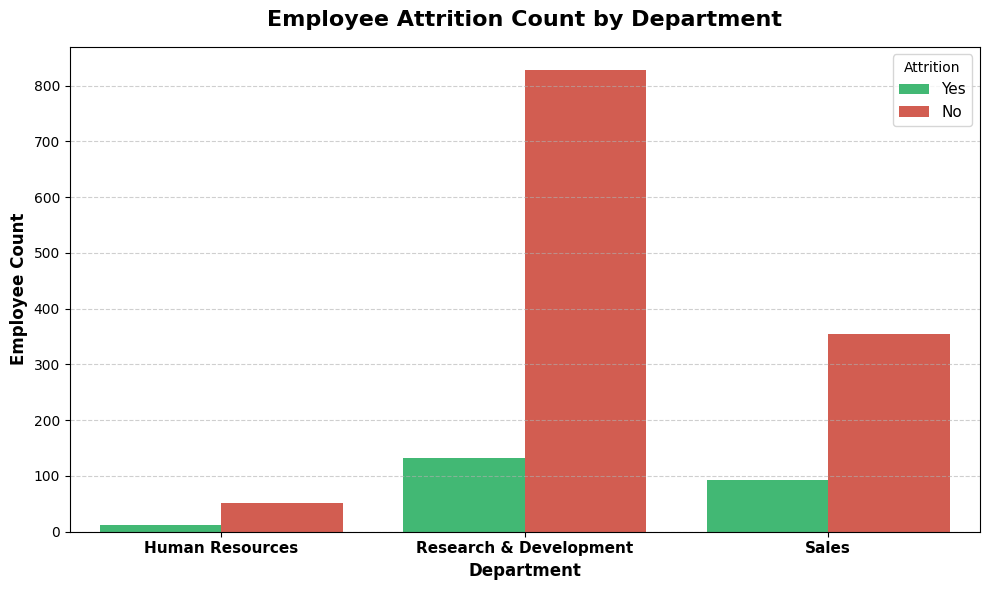

In [8]:
#رسمة نسبة الاستقالات حسب قسم العمل (Attrition by Department)
plt.figure(figsize=(10, 6))
sns.countplot(x='Department', hue='Attrition', data=df, palette=['#2ecc71', '#e74c3c'])

plt.title('Employee Attrition Count by Department', fontsize=16, weight='bold', pad=15)
plt.xlabel('Department', fontsize=12, weight='bold')
plt.ylabel('Employee Count', fontsize=12, weight='bold')
plt.xticks(fontsize=11, weight='bold')
plt.legend(title='Attrition', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2701/1750708572.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='OverTime', y='Attrition_Num', data=df, palette='Reds_r', ci=None, hue='OverTime', legend=False)


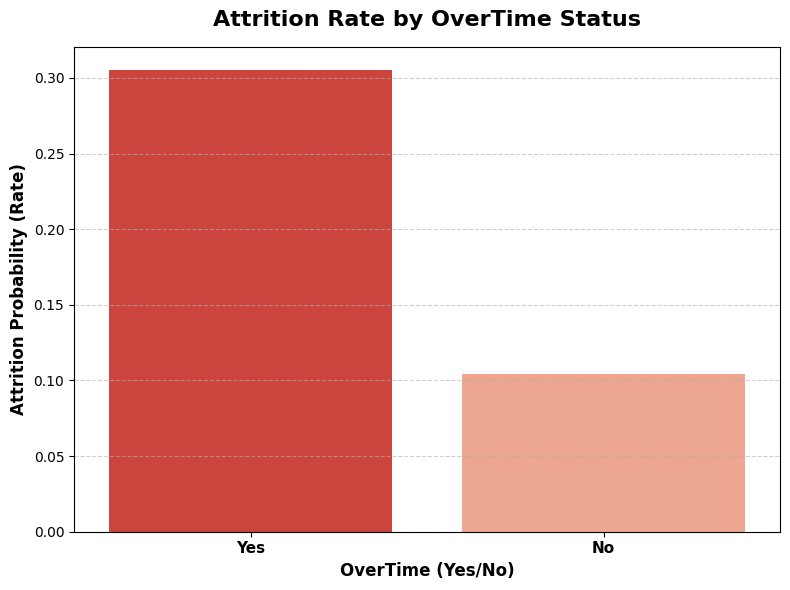

In [9]:
#تأثير ساعات العمل الإضافية على الاستقالة (OverTime vs Attrition)
plt.figure(figsize=(8, 6))
sns.barplot(x='OverTime', y='Attrition_Num', data=df, palette='Reds_r', ci=None, hue='OverTime', legend=False)

plt.title('Attrition Rate by OverTime Status', fontsize=16, weight='bold', pad=15)
plt.xlabel('OverTime (Yes/No)', fontsize=12, weight='bold')
plt.ylabel('Attrition Probability (Rate)', fontsize=12, weight='bold')
plt.xticks(fontsize=11, weight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

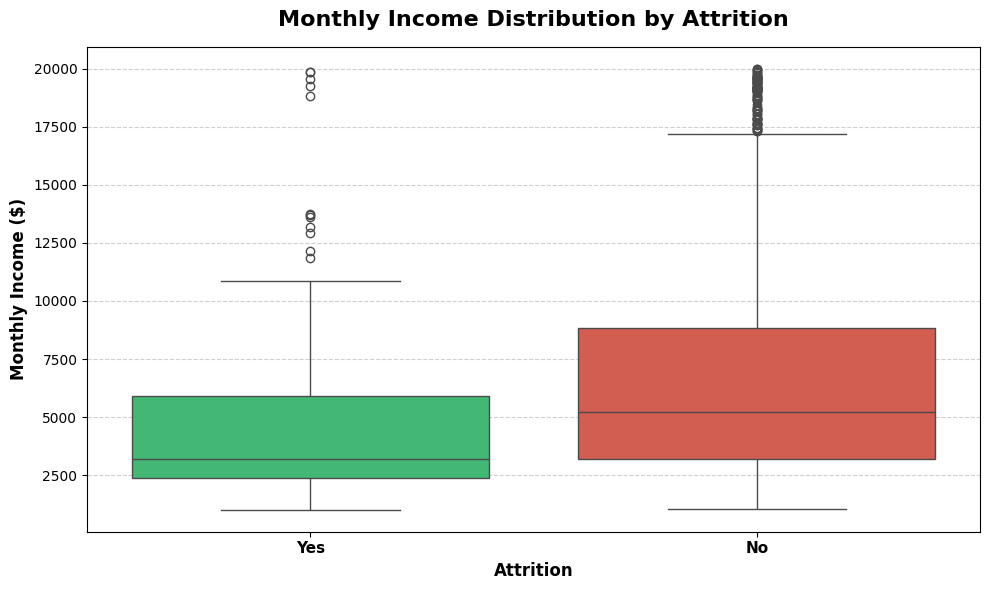

In [10]:
#مقارنة رواتب الموظفين الذين استقالوا مقارنة بالباقين
plt.figure(figsize=(10, 6))
sns.boxplot(x='Attrition', y='MonthlyIncome', data=df, palette=['#2ecc71', '#e74c3c'], hue='Attrition', legend=False)

plt.title('Monthly Income Distribution by Attrition', fontsize=16, weight='bold', pad=15)
plt.xlabel('Attrition', fontsize=12, weight='bold')
plt.ylabel('Monthly Income ($)', fontsize=12, weight='bold')
plt.xticks(fontsize=11, weight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

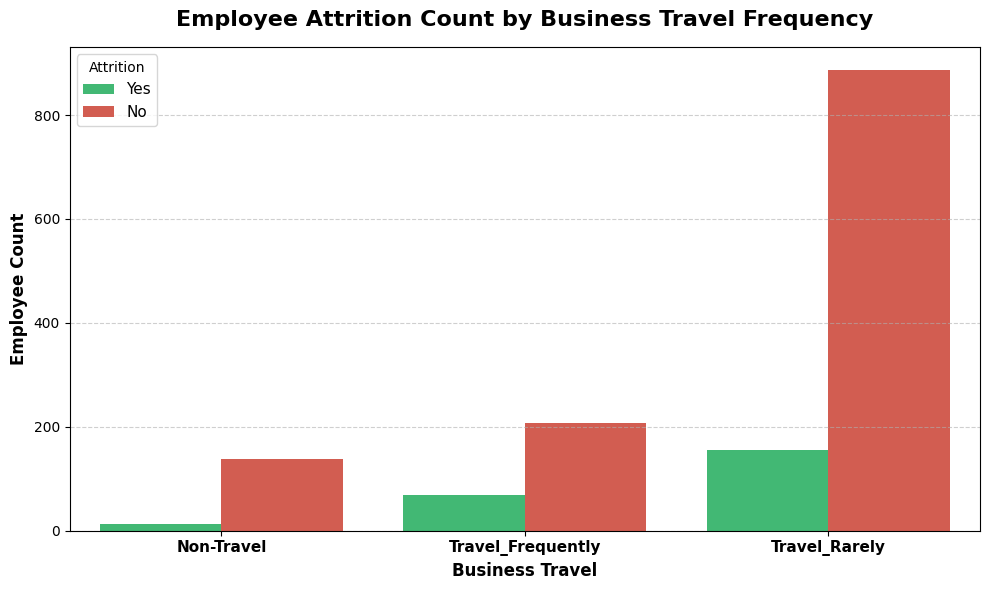

In [11]:
# رسمة توضح نسبة الاستقالة بناءً على معدل سفر الموظفين لطبيعة العمل
plt.figure(figsize=(10, 6))
sns.countplot(x='BusinessTravel', hue='Attrition', data=df, palette=['#2ecc71', '#e74c3c'])

plt.title('Employee Attrition Count by Business Travel Frequency', fontsize=16, weight='bold', pad=15)
plt.xlabel('Business Travel', fontsize=12, weight='bold')
plt.ylabel('Employee Count', fontsize=12, weight='bold')
plt.xticks(fontsize=11, weight='bold')
plt.legend(title='Attrition', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

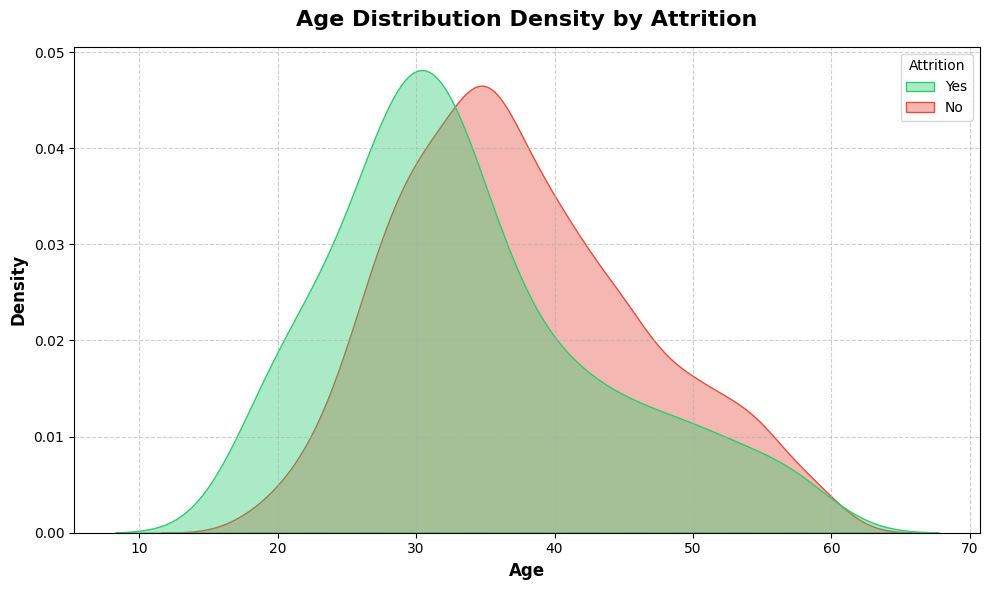

In [12]:
# رسمة توزيع أعمار الموظفين ومقارنتها بين من استقالوا ومن بقوا في الشركة
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='Age', hue='Attrition', fill=True, common_norm=False, palette=['#2ecc71', '#e74c3c'], alpha=0.4)

plt.title('Age Distribution Density by Attrition', fontsize=16, weight='bold', pad=15)
plt.xlabel('Age', fontsize=12, weight='bold')
plt.ylabel('Density', fontsize=12, weight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

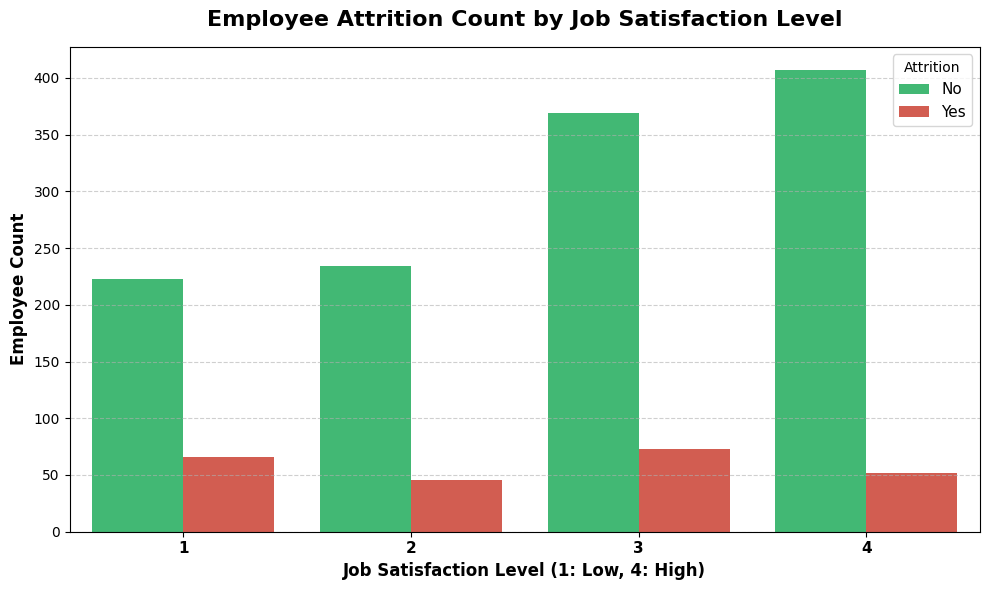

In [13]:
# رسمة توضح علاقة مستوى الرضا الوظيفي بحالات الاستقالة
plt.figure(figsize=(10, 6))
sns.countplot(x='JobSatisfaction', hue='Attrition', data=df, palette=['#2ecc71', '#e74c3c'])

plt.title('Employee Attrition Count by Job Satisfaction Level', fontsize=16, weight='bold', pad=15)
plt.xlabel('Job Satisfaction Level (1: Low, 4: High)', fontsize=12, weight='bold')
plt.ylabel('Employee Count', fontsize=12, weight='bold')
plt.xticks(fontsize=11, weight='bold')
plt.legend(title='Attrition', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

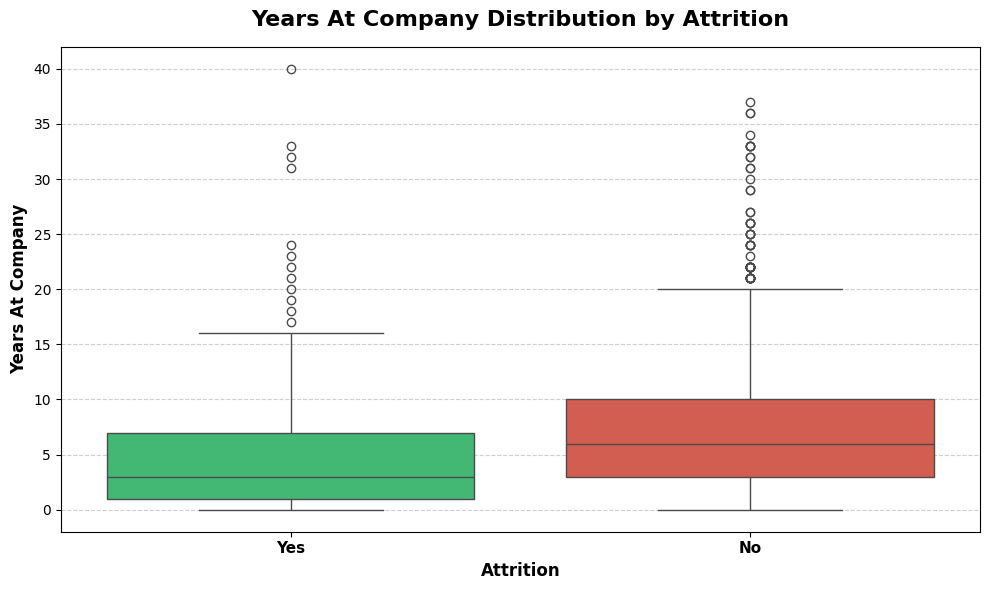

In [14]:
# رسمة توضح توزيع سنوات بقاء الموظف في الشركة مقارنة بالاستقالة
plt.figure(figsize=(10, 6))
sns.boxplot(x='Attrition', y='YearsAtCompany', data=df, palette=['#2ecc71', '#e74c3c'], hue='Attrition', legend=False)

plt.title('Years At Company Distribution by Attrition', fontsize=16, weight='bold', pad=15)
plt.xlabel('Attrition', fontsize=12, weight='bold')
plt.ylabel('Years At Company', fontsize=12, weight='bold')
plt.xticks(fontsize=11, weight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

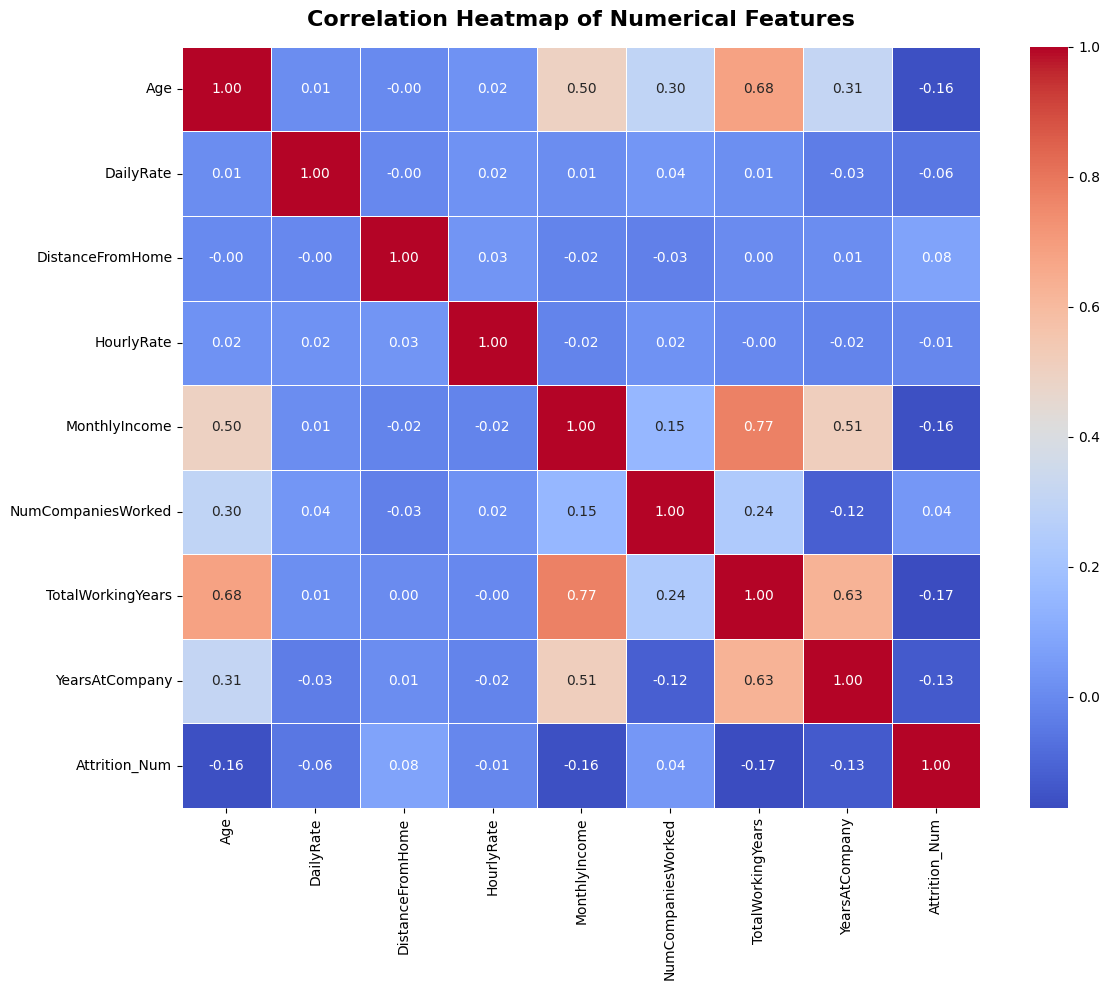

In [15]:
# خريطة حرارية توضح مصفوفة الارتباط بين المتغيرات العددية الرئيسية
plt.figure(figsize=(12, 10))
numeric_cols = ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome',
                'NumCompaniesWorked', 'TotalWorkingYears', 'YearsAtCompany', 'Attrition_Num']
corr_matrix = df[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, cbar=True)

plt.title('Correlation Heatmap of Numerical Features', fontsize=16, weight='bold', pad=15)
plt.tight_layout()
plt.show()

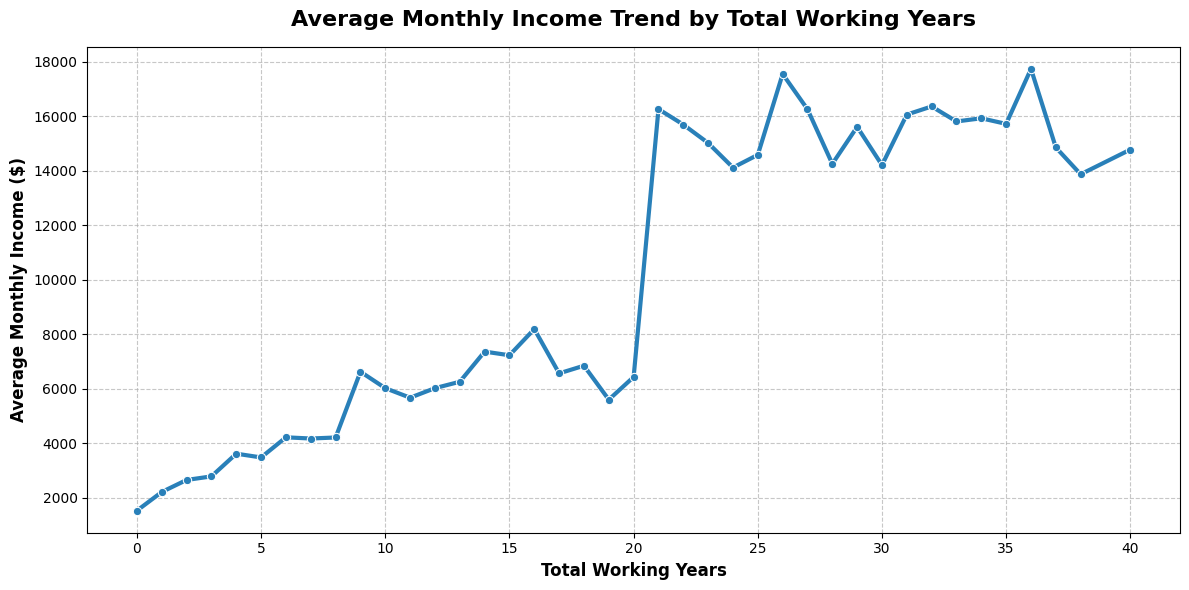

In [16]:
# رسمة خطية توضح العلاقة بين سنوات الخبرة ومتوسط الدخل الشهري للموظفين
plt.figure(figsize=(12, 6))
income_by_experience = df.groupby('TotalWorkingYears')['MonthlyIncome'].mean().reset_index()

sns.lineplot(data=income_by_experience, x='TotalWorkingYears', y='MonthlyIncome', color='#2980b9', linewidth=3, marker='o', markersize=6)

plt.title('Average Monthly Income Trend by Total Working Years', fontsize=16, weight='bold', pad=15)
plt.xlabel('Total Working Years', fontsize=12, weight='bold')
plt.ylabel('Average Monthly Income ($)', fontsize=12, weight='bold')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

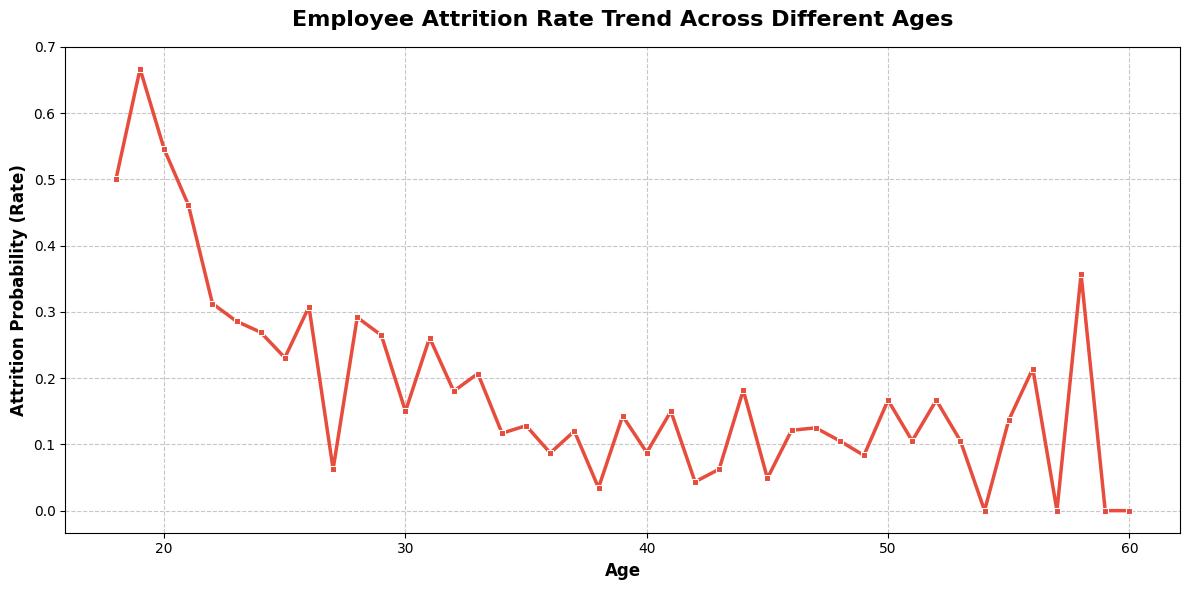

In [17]:
# رسمة خطية توضح معدل الاستقالة حسب عمر الموظفين
plt.figure(figsize=(12, 6))
age_attrition = df.groupby('Age')['Attrition_Num'].mean().reset_index()

sns.lineplot(data=age_attrition, x='Age', y='Attrition_Num', color='#e74c3c', linewidth=2.5, marker='s', markersize=5)

plt.title('Employee Attrition Rate Trend Across Different Ages', fontsize=16, weight='bold', pad=15)
plt.xlabel('Age', fontsize=12, weight='bold')
plt.ylabel('Attrition Probability (Rate)', fontsize=12, weight='bold')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()